# AI-Powered Construction Site Hazard Anticipation
### Video Understanding, Worker Trajectory Analysis, and Rule-Based Risk Monitoring

## Executive Summary

Construction-site safety teams need ways to review video footage and identify situations that may require attention. This notebook builds a **computer-vision prototype** that processes one uploaded video, detects visible objects, tracks detections over time, analyzes person trajectories, and checks whether tracked people enter a configurable image region.

The implemented workflow uses:
- A pretrained YOLO model for frame-level object detection
- ByteTrack for associating detections across consecutive frames
- Pandas and NumPy for tracking and movement features
- Matplotlib for trajectory and monitoring visualizations
- A transparent duration-based rule for classifying sample-zone intrusion episodes

The current notebook demonstrates **person detection, tracking, trajectory analysis, and manually configured sample-zone monitoring**. It does not yet demonstrate validated worker–machinery interaction detection or a trained accident-prediction model.

### Implemented outputs

- Object detections from a sample frame
- Frame-by-frame tracking records
- Track and object summaries
- Worker movement features and trajectory plots
- Sample restricted-zone observations
- Rule-based intrusion event report
- Safety monitoring charts and exported CSV/PNG files

> **Scope and safety note:** This is an educational prototype, not a certified safety system. Its sample zone and duration thresholds are illustrative. No accident probability, real-world safety violation, or prevention claim is established by this notebook.


## How to Read This Notebook

Each implementation cell is introduced by a short guide that states:
- **Input:** what data or variables the cell receives
- **Process:** what the code does and the main technique used
- **Output:** what table, plot, file, or message is produced
- **Inference:** what the result means, what it does not mean, and what to check before moving on

Read the notebook from top to bottom and run cells in order. Most cells depend on variables created earlier. If you restart the Colab runtime, rerun the notebook from the beginning.

**Reproducibility note:** The exact outputs depend on the uploaded video, model version, package versions, confidence threshold, and tracker configuration. The numerical results documented in the interpretation notes refer to the run summarized in this notebook; a new run may produce different values.


## 1. Business Problem

Construction-site video contains information about people, equipment, and movement. Reviewing footage manually can be time-consuming, while a single image only shows one moment and does not describe how an object moves over time.

This project explores a focused first step: **can computer vision automatically locate and track people in a video, summarize their movement, and flag observations that fall inside a configured image region?**

### Why this matters

- Safety teams may need to review long recordings.
- Object detection identifies visible objects but does not preserve their movement history.
- Tracking provides a sequence of positions for each detected object.
- A configurable region check can help demonstrate how a site-specific monitoring rule might work.

### Business value of the prototype

The notebook creates structured tracking records and a repeatable event report that can support video review and further safety analytics.

The current video and model outputs do **not** establish a real hazardous worker–machinery interaction. That capability requires suitable footage, construction-specific detection, and independently labelled events.


## 2. Project Objectives and Scope

### Objectives implemented in this notebook

1. Load and inspect a recorded video.
2. Run a pretrained YOLO model on a sample frame.
3. Track detected objects across the video using ByteTrack.
4. Store bounding boxes, confidence, class labels, track IDs, and timestamps.
5. Summarize object tracks and inspect their trajectories.
6. Engineer pixel-based movement features for the two substantial person tracks observed in this run.
7. Apply a configurable rectangular sample zone to person footpoints.
8. Group consecutive in-zone observations into episodes and assign transparent duration-based scores.
9. Export data tables and visual outputs.

### Not implemented / future scope

- Construction-specific model training or fine-tuning
- Reliable PPE compliance detection
- Validated worker–vehicle or worker–machinery proximity detection
- Physical distance or speed estimation in metres/metres per second
- Supervised accident prediction or calibrated accident probabilities
- Multi-camera identity matching or production CCTV deployment

### Research direction

The longer-term research question is whether motion, context, and independently labelled safety events can support early identification of hazardous interactions. The current notebook is a foundation for that future work, not proof that the question has already been solved.


## 3. Implemented Solution: End-to-End Workflow

The notebook follows this sequence:

1. **Video input:** upload one recorded clip and inspect its properties.
2. **Object detection:** use pretrained YOLO to detect objects in a sample frame.
3. **Object tracking:** run ByteTrack across the video and record track identities.
4. **Data audit:** inspect the resulting tracking table, classes, IDs, and missing values.
5. **Movement analysis:** calculate image-coordinate displacement and trajectory summaries for person tracks.
6. **Sample-zone monitoring:** test whether each person's bottom-centre point falls inside a manually configured rectangle.
7. **Event reporting:** group consecutive in-zone observations and apply a duration-based demonstration score.
8. **Dashboard and export:** visualize the results and save CSV/PNG deliverables.

### Important distinction

Detection answers **“what appears in this frame?”** Tracking answers **“which detections are associated across frames?”** Zone monitoring answers **“did a tracked footpoint fall inside this configured rectangle?”** None of these alone predicts an accident.


## Code Cell 1 — What this step does

**Input:** Previous cell outputs.  
**Process:** Executes the code shown below.  
**Output:** See the cell output.  
**Inference:** Interpret the output in the context of the project scope and limitations.

In [1]:
from IPython.display import display, HTML

display(HTML("""
<div style="font-family:Arial; max-width:720px; margin:auto; text-align:center;">
  <div style="border:1px solid #64748b; padding:14px; border-radius:9px;">
    <b>1. Uploaded Video</b><br><small>One recorded clip</small>
  </div>
  <div style="font-size:24px; padding:5px;">↓</div>
  <div style="border:1px solid #64748b; padding:14px; border-radius:9px;">
    <b>2. YOLO Object Detection</b><br><small>Frame-level classes and bounding boxes</small>
  </div>
  <div style="font-size:24px; padding:5px;">↓</div>
  <div style="border:1px solid #64748b; padding:14px; border-radius:9px;">
    <b>3. ByteTrack</b><br><small>Track IDs across consecutive frames</small>
  </div>
  <div style="font-size:24px; padding:5px;">↓</div>
  <div style="border:1px solid #64748b; padding:14px; border-radius:9px;">
    <b>4. Trajectory and Movement Analysis</b><br><small>Image-coordinate positions and displacement</small>
  </div>
  <div style="font-size:24px; padding:5px;">↓</div>
  <div style="border:1px solid #64748b; padding:14px; border-radius:9px;">
    <b>5. Sample Restricted-Zone Rule</b><br><small>Point-in-rectangle check and duration grouping</small>
  </div>
  <div style="font-size:24px; padding:5px;">↓</div>
  <div style="background:#dcfce7; color:#14532d; padding:14px; border-radius:9px;">
    <b>6. Reports and Visualizations</b><br><small>Tracking CSV, event report, charts and exports</small>
  </div>
</div>
"""))

### Inference / interpretation

Review the output and confirm that it matches the intended step before continuing.

## 4. Success Criteria and Evaluation Boundaries

| Component | What this notebook demonstrates | What would be needed for formal evaluation |
|---|---|---|
| Object detection | YOLO predictions on a sample frame | Manually labelled frames and detection metrics |
| Tracking | Track IDs and track histories | Ground-truth identities and IDF1/HOTA or identity-switch review |
| Trajectory analysis | Pixel-coordinate paths and displacement | Camera calibration for physical units; manual trajectory checks |
| Zone monitoring | Point-in-rectangle rule | A zone defined by site safety personnel and verified video coordinates |
| Risk-event classification | Illustrative duration-based score | Independently labelled unsafe events and validation data |
| Accident prediction | Not implemented | Time-stamped future-event labels, train/test separation, calibrated evaluation |

### Evaluation principle

A working notebook is not evidence of predictive accuracy. The current risk score is a deterministic rule based on the duration of a sample-zone episode. It is not a trained model, an accident probability, or a recognized safety standard.

The notebook should report observed outputs and limitations honestly. Precision, recall, F1, PR-AUC, or warning lead time should only be reported when suitable ground-truth labels exist.



## 5. Development Environment

This project uses Google Colab as its development environment.

Colab provides a notebook interface for executing Python code and may
provide access to a GPU for accelerating deep-learning inference.

### Tools and their purposes

- Python: primary programming language
- OpenCV: video reading and frame processing
- Ultralytics YOLO: object detection and tracking
- NumPy: numerical calculations
- Pandas: structured data and trajectory tables
- Matplotlib: visual analysis
- Scikit-learn: optional supervised risk classification and evaluation

We will first validate the video-processing pipeline with a pretrained
model. Model training will be considered only after the data and
evaluation strategy are established.


## Cell 7 — Install the required libraries

**Input:** The Colab Python runtime and the package names in the command.  
**Process:** `pip` installs Ultralytics, OpenCV, Pandas, NumPy, Matplotlib, and Scikit-learn.  
**Output:** Installation messages (quiet mode suppresses most details).  
**Inference:** This prepares the environment; it does not load data, train a model, or prove GPU availability.

In [2]:

%pip install -q ultralytics opencv-python-headless pandas numpy matplotlib scikit-learn


### Inference / interpretation

If installation completes without an error, the required packages are available in this runtime. If installation fails, resolve that before proceeding.

Inference: We have installed the core dependencies for video analysis and modeling. Installation success does not yet establish that the GPU is available or that the input video is suitable.

## Cell 9 — Import libraries

**Input:** The packages installed in the previous cell.  
**Process:** Imports video I/O, tensor/GPU support, arrays, tables, plotting, YOLO, and optional evaluation utilities.  
**Output:** Package versions and a success message.  
**Inference:** The notebook can now use these libraries. No video has been analyzed yet.

In [3]:

import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Image, Markdown

from ultralytics import YOLO
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report
)

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully.
PyTorch version: 2.11.0+cu130
OpenCV version: 4.14.0


### Inference / interpretation

Version numbers help make the environment reproducible. A successful import confirms package availability, not model correctness.

Inference: The tools required for video processing, numerical analysis and later evaluation are available. We have not yet loaded or analyzed any project data.

## Cell 11 — Check hardware acceleration

**Input:** The PyTorch runtime and its CUDA availability status.  
**Process:** Checks whether CUDA is available and, if so, retrieves the GPU name.  
**Output:** Either the available GPU name or a CPU fallback message.  
**Inference:** A GPU can accelerate model inference, but CPU execution is also possible and may be slower. This cell does not benchmark performance.

In [4]:

import torch

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Running on CPU.")

GPU available: Tesla T4


### Inference / interpretation

A Tesla T4 or another CUDA device means GPU inference can be selected. If no GPU is available, the notebook falls back to CPU.


## 6. Data Understanding

The input to our system is construction-site video.

However, not all datasets can answer the same questions.

An image dataset may help evaluate object detection, but it cannot by
itself demonstrate how a worker moves across time.

Similarly, a video containing workers and vehicles does not automatically
provide ground-truth labels for future near-miss events.

We therefore distinguish between:

1. **Perception data:** images or frames used to inspect object detection.
2. **Motion data:** consecutive video frames used for tracking and trajectories.
3. **Risk-event labels:** independently reviewed timestamps identifying
   hazardous interactions and their occurrence times.

We will select video that visibly contains workers and moving machinery.
We will document the source and license, inspect the footage, and determine
whether the selected clips contain enough evidence to evaluate our research
question.


## Cell 13 — Create the project folders

**Input:** The intended project directory structure.  
**Process:** Creates `data/videos`, `outputs`, and `reports` under the Colab project directory. `exist_ok=True` allows the cell to be rerun.  
**Output:** The folder paths.  
**Inference:** The notebook now has organized locations for input videos and generated artifacts. The folders are in the temporary Colab runtime unless separately saved to Drive.

In [5]:
from pathlib import Path

PROJECT_DIR = Path("/content/construction_hazard_project")

DATA_DIR = PROJECT_DIR / "data"
VIDEO_DIR = DATA_DIR / "videos"
OUTPUT_DIR = PROJECT_DIR / "outputs"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [VIDEO_DIR, OUTPUT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Video directory:", VIDEO_DIR)
print("Output directory:", OUTPUT_DIR)
print("Report directory:", REPORT_DIR)

Project directory: /content/construction_hazard_project
Video directory: /content/construction_hazard_project/data/videos
Output directory: /content/construction_hazard_project/outputs
Report directory: /content/construction_hazard_project/reports


### Inference / interpretation

The folders are now ready. Colab storage is temporary, so important outputs must be downloaded or copied to Google Drive.

## Cell 14 — Upload the video

**Input:** A video file selected from your computer through the Colab upload dialog.  
**Process:** Reads the uploaded bytes and writes each file into the project's video folder.  
**Output:** The saved file path for each uploaded file.  
**Inference:** Uploading only transfers the file; the next cell selects a supported video file for analysis.

In [7]:

from google.colab import files

uploaded = files.upload()

for filename, content in uploaded.items():
    destination = VIDEO_DIR / filename

    with open(destination, "wb") as f:
        f.write(content)

    print("Saved:", destination)


Saving 13752039_3840_2160_50fps.mp4 to 13752039_3840_2160_50fps.mp4
Saved: /content/construction_hazard_project/data/videos/13752039_3840_2160_50fps.mp4


### Inference / interpretation

Confirm that the expected video filename appears. If the upload dialog was cancelled, no input video was saved.

## Cell 15 — Select the video file

**Input:** Files in the project's video folder.  
**Process:** Searches for MP4, AVI, MOV, and MKV files, raises an error if none is found, and selects the first matching file.  
**Output:** The selected filename and file size.  
**Inference:** The pipeline will analyze one selected clip in this run. If multiple clips are uploaded, this code does not automatically process all of them.

In [8]:

video_files = (
    list(VIDEO_DIR.glob("*.mp4"))
    + list(VIDEO_DIR.glob("*.avi"))
    + list(VIDEO_DIR.glob("*.mov"))
    + list(VIDEO_DIR.glob("*.mkv"))
)

if not video_files:
    raise FileNotFoundError(
        "No video found. Upload an MP4, AVI, MOV, or MKV file first."
    )

VIDEO_PATH = video_files[0]

print("Selected video:", VIDEO_PATH.name)
print("File size (MB):", round(VIDEO_PATH.stat().st_size / (1024**2), 2))


Selected video: 13752039_3840_2160_50fps.mp4
File size (MB): 22.05


### Inference / interpretation

Check that the selected filename is the intended clip. If multiple videos exist, the first matching file is selected rather than all videos.

## Cell 16 — Read video metadata

**Input:** `VIDEO_PATH`, the selected video file.  
**Process:** OpenCV reads frame rate, total frame count, width, and height; duration is calculated as frame count divided by FPS when FPS is valid.  
**Output:** Resolution, frame count, FPS, and estimated duration.  
**Inference:** These properties describe the video and provide the timing basis for later timestamps. Incorrect or missing FPS can affect time calculations.

In [9]:
import cv2

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise ValueError("Unable to open the selected video.")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration_seconds = frame_count / fps if fps and fps > 0 else None

print("Resolution:", f"{width} × {height}")
print("Frames:", frame_count)
print("FPS:", fps)
print(
    "Duration (seconds):",
    round(duration_seconds, 2) if duration_seconds is not None else "Unknown"
)

cap.release()

Resolution: 3840 × 2160
Frames: 516
FPS: 50.0
Duration (seconds): 10.32


### Inference / interpretation

Use the reported FPS and duration to understand the temporal coverage. Timestamp calculations later assume this FPS is valid.

## Cell 17 — Inspect representative frames

**Input:** The video and its frame count.  
**Process:** Selects up to four evenly spaced frame indices, reads those frames, converts BGR to RGB, and displays them.  
**Output:** A visual sample of the clip.  
**Inference:** This is a qualitative check of video content and image quality. It helps decide whether the clip is suitable, but does not evaluate detector accuracy.

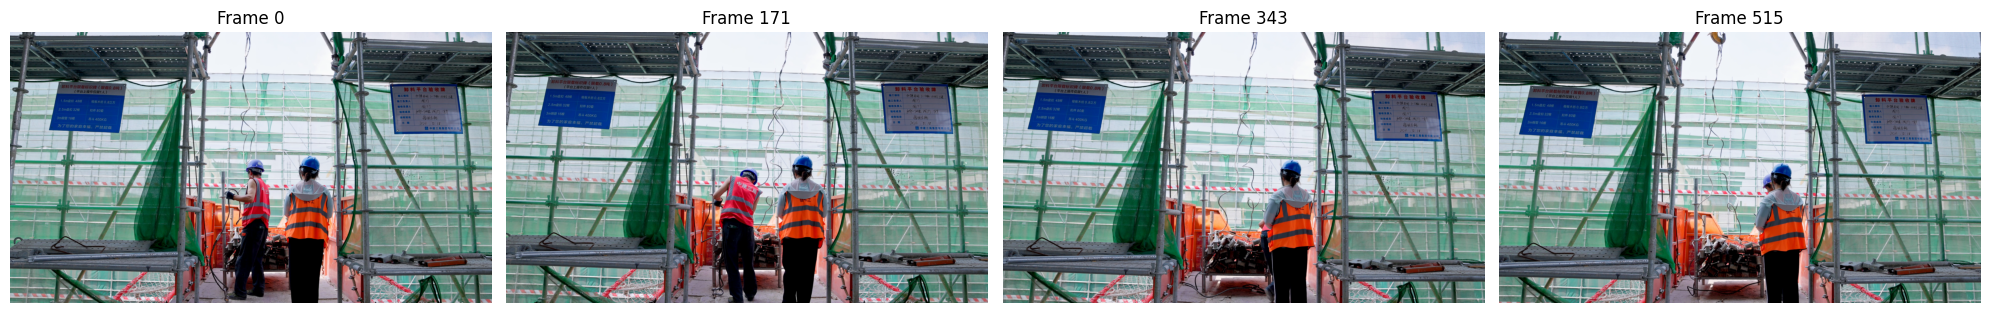

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise ValueError("Unable to open the video.")

if frame_count <= 0:
    raise ValueError("The video contains no readable frames.")

sample_indices = np.linspace(
    0,
    max(frame_count - 1, 0),
    num=min(4, frame_count),
    dtype=int
)

fig, axes = plt.subplots(
    1, len(sample_indices),
    figsize=(5 * len(sample_indices), 4)
)

axes = np.atleast_1d(axes)

for ax, frame_index in zip(axes, sample_indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
    success, frame = cap.read()

    if success:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame_rgb)
        ax.set_title(f"Frame {frame_index}")
        ax.axis("off")
    else:
        ax.set_title(f"Could not read frame {frame_index}")
        ax.axis("off")

plt.tight_layout()
plt.show()

cap.release()

### Inference / interpretation

Use these frames to verify that the video contains the scene and objects relevant to the intended analysis. If it does not, choose a more suitable clip.


## 7. Object Detection: Understanding the Scene

Before estimating risk, the system must identify the objects involved.

We use a pretrained YOLO object-detection model. It predicts bounding
boxes around visible objects, assigns class labels, and estimates
confidence scores for those detections.

For this project, the most important classes are people and relevant
vehicles.

The model is pretrained, so we are reusing learned visual features
rather than training an object detector from scratch.

A detection is not a hazard prediction. It tells us what the model
believes is visible in the current frame, not what will happen next.


## Cell 19 — Load the pretrained YOLO model

**Input:** The model identifier `yolo11n.pt`.  
**Process:** Ultralytics loads pretrained YOLO11 nano weights and exposes the model's class-name mapping.  
**Output:** A model-loaded message and available class names.  
**Inference:** The model is pretrained on general object categories. It has not been trained specifically for construction hazards in this notebook.

In [15]:
%pip install -q ultralytics
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO model loaded.")
print("Available class names:")
print(model.names)

YOLO model loaded.
Available class names:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66:

### Inference / interpretation

The available class list describes the pretrained model's vocabulary. It is not a construction-specific label set.

## Cell 20 — Run object detection on one frame

**Input:** The first readable frame from `VIDEO_PATH`, the loaded YOLO model, and confidence threshold `0.25`.  
**Process:** YOLO predicts bounding boxes and classes on that frame, using the GPU if available. The prediction is drawn over the frame.  
**Output:** An annotated frame with boxes and labels.  
**Inference:** This is a single-frame demonstration of what the model recognizes. A detected person is not automatically a worker, and a class prediction is not a hazard event.

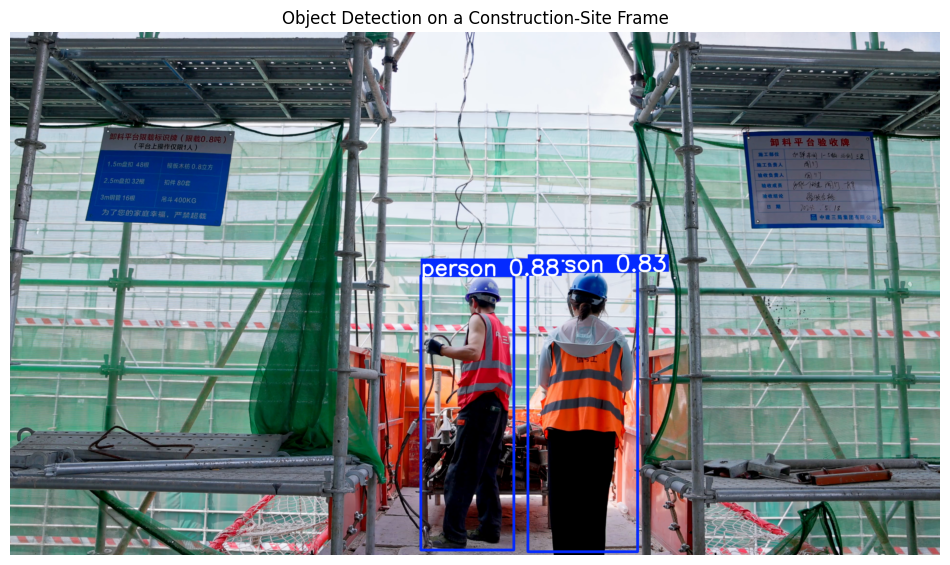

In [12]:

cap = cv2.VideoCapture(str(VIDEO_PATH))

success, frame = cap.read()
cap.release()

if not success:
    raise ValueError("Could not read the first frame.")

device = 0 if torch.cuda.is_available() else "cpu"

results = model.predict(
    source=frame,
    conf=0.25,
    device=device,
    verbose=False
)

annotated_frame = results[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title("Object Detection on a Construction-Site Frame")
plt.axis("off")
plt.show()


### Inference / interpretation

Inspect missed objects and false detections visually. The model's prediction is only a starting point for later analysis.

## Cell 21 — Convert detections into a table

**Input:** The detection boxes from Cell 20.  
**Process:** Extracts class ID/name, confidence, and bounding-box coordinates (`x1`, `y1`, `x2`, `y2`) for each detection.  
**Output:** `detections_df`, one row per detected object in the sample frame.  
**Inference:** The table makes model output available for analysis. The number of rows is the number of detections in this frame only, not the number of objects in the entire video.

In [13]:

detection_rows = []

for box in results[0].boxes:
    class_id = int(box.cls.item())
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    confidence = float(box.conf.item())

    detection_rows.append({
        "class_id": class_id,
        "class_name": model.names[class_id],
        "confidence": confidence,
        "x1": float(x1),
        "y1": float(y1),
        "x2": float(x2),
        "y2": float(y2)
    })

detections_df = pd.DataFrame(detection_rows)

display(detections_df.head(10))
print("Number of detections:", len(detections_df))


,class_id,class_name,confidence,x1,y1,x2,y2
0,0,person,0.884683,1696.712646,1008.894653,2080.653320,2139.151855
1,0,person,0.830477,2138.769287,991.068604,2591.387695,2146.258301


Number of detections: 2


### Inference / interpretation

Each row describes one object in one frame. Confidence should be interpreted as the detector's model score, not a calibrated probability.

## Cell 22 — Initialize video object tracking

**Input:** The selected video, YOLO model, ByteTrack configuration, confidence threshold, and compute device.  
**Process:** Calls `model.track` with streaming enabled and persistent tracking state. The returned generator is consumed in the next cell.  
**Output:** A tracking-results generator and an initialization message.  
**Inference:** Track IDs are assigned within this video-processing run. They are not permanent identities and should not be compared across cameras or separate videos.

In [16]:

tracking_results = model.track(
    source=str(VIDEO_PATH),
    tracker="bytetrack.yaml",
    conf=0.25,
    device=device,
    stream=True,
    persist=True,
    verbose=False
)

print("Tracking pipeline initialized.")
print("Next, we will process the returned frames and record track history.")


Tracking pipeline initialized.
Next, we will process the returned frames and record track history.


### Inference / interpretation

The tracking generator is ready. The actual per-frame records are created only when the next cell iterates through it.

## Cell 23 — Process frames and build the tracking table

**Input:** The tracking-results generator and the video's FPS.  
**Process:** Iterates through frames, reads bounding boxes, track IDs, classes, and confidence scores, calculates timestamps and box reference points, and appends records to `track_rows`. It then creates `tracks_df`.  
**Output:** A frame-level tracking DataFrame with coordinates, class information, IDs, and timestamps.  
**Inference:** Each row represents one tracked-object observation in one frame. Repeated rows for the same ID form its observed history. Tracking quality still needs visual inspection; short tracks or false detections may occur.

In [17]:

track_rows = []
sample_frames = []

cap = cv2.VideoCapture(str(VIDEO_PATH))
video_fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()

if not video_fps or video_fps <= 0:
    raise ValueError("A valid video FPS is required for time calculations.")

for frame_idx, result in enumerate(tracking_results):
    if frame_idx % 100 == 0:
        print("Processed frame:", frame_idx)

    boxes = result.boxes

    if boxes is not None and boxes.id is not None:
        xyxy = boxes.xyxy.cpu().numpy()
        ids = boxes.id.cpu().numpy().astype(int)
        classes = boxes.cls.cpu().numpy().astype(int)
        confidences = boxes.conf.cpu().numpy()

        for coords, track_id, class_id, confidence in zip(
            xyxy, ids, classes, confidences
        ):
            x1, y1, x2, y2 = coords

            track_rows.append({
                "frame": frame_idx,
                "timestamp": frame_idx / video_fps,
                "track_id": int(track_id),
                "class_id": int(class_id),
                "class_name": model.names[int(class_id)],
                "confidence": float(confidence),
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2),
                "center_x": float((x1 + x2) / 2),
                "center_y": float((y1 + y2) / 2),
                "bottom_x": float((x1 + x2) / 2),
                "bottom_y": float(y2)
            })

    if frame_idx % max(int(video_fps * 2), 1) == 0:
        sample_frames.append((frame_idx, result.plot()))

tracks_df = pd.DataFrame(track_rows)

if tracks_df.empty:
    raise ValueError(
        "No tracked objects were recorded. Check the video, detector, "
        "confidence threshold, and tracker configuration."
    )

display(tracks_df.head())
print("Tracked observations:", len(tracks_df))
print("Unique track IDs:", tracks_df["track_id"].nunique())


Processed frame: 0
Processed frame: 100
Processed frame: 200
Processed frame: 300
Processed frame: 400
Processed frame: 500


,frame,timestamp,track_id,class_id,class_name,confidence,x1,y1,x2,y2,center_x,center_y,bottom_x,bottom_y
0,0,0.00,1,0,person,0.884683,1696.712646,1008.894592,2080.653320,2139.151855,1888.682983,1574.023193,1888.682983,2139.151855
1,0,0.00,2,0,person,0.830477,2138.769287,991.068604,2591.387939,2146.258301,2365.078613,1568.663452,2365.078613,2146.258301
2,1,0.02,1,0,person,0.881939,1692.636841,1011.982422,2076.302246,2141.857910,1884.469482,1576.920166,1884.469482,2141.857910
3,1,0.02,2,0,person,0.829599,2138.325928,989.923950,2591.722656,2147.349609,2365.024414,1568.636719,2365.024414,2147.349609
4,2,0.04,1,0,person,0.879134,1692.001587,1015.024353,2073.467285,2139.492188,1882.734375,1577.258301,1882.734375,2139.492188


Tracked observations: 837
Unique track IDs: 3


### Inference / interpretation

The resulting table is the central dataset for the remaining notebook. Inspect a few annotated frames or track sequences if identity switches are suspected.

## Cell 24 — Visualize all tracked-object trajectories

**Input:** `tracks_df`, grouped by `track_id`.  
**Process:** Sorts each track by timestamp and plots its bottom-centre coordinates when it has at least three observations.  
**Output:** A trajectory line for each sufficiently long track.  
**Inference:** The plot helps inspect where tracked objects moved in image coordinates. Irregular jumps can reflect real movement, detector jitter, or tracking errors. Coordinates are pixels, not metres.

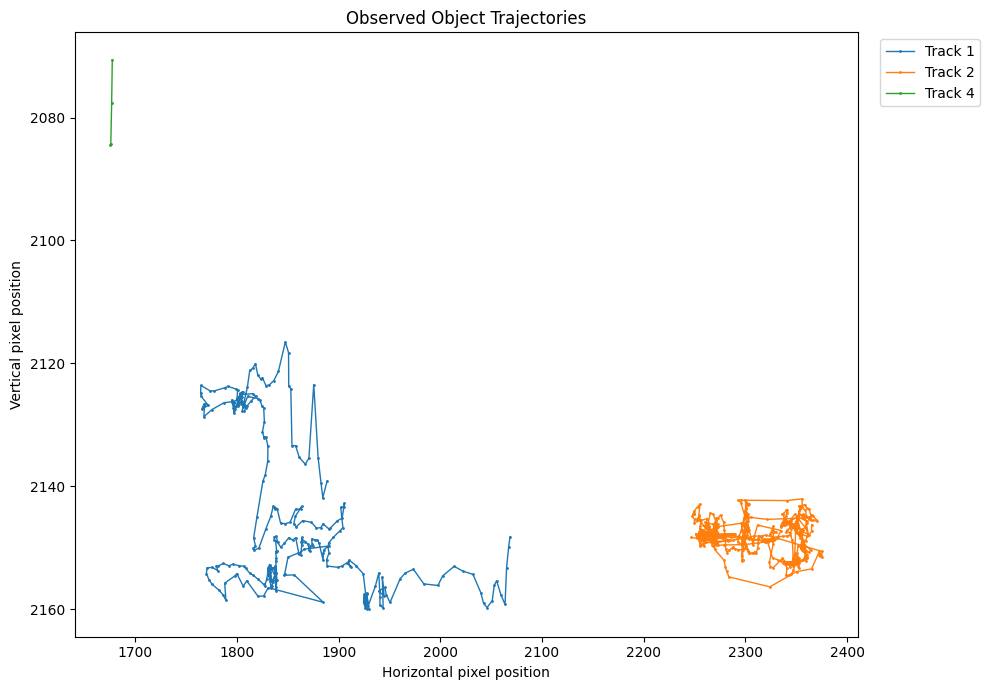

In [18]:


plt.figure(figsize=(10, 7))

for track_id, group in tracks_df.groupby("track_id"):
    group = group.sort_values("timestamp")

    if len(group) < 3:
        continue

    plt.plot(
        group["bottom_x"],
        group["bottom_y"],
        marker=".",
        markersize=2,
        linewidth=1,
        label=f"Track {track_id}"
    )

plt.gca().invert_yaxis()
plt.xlabel("Horizontal pixel position")
plt.ylabel("Vertical pixel position")
plt.title("Observed Object Trajectories")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Inference / interpretation

A smooth line can suggest consistent tracking; abrupt jumps or isolated segments should be reviewed as potential tracking noise.

## Cell 25 — Summarize track duration and confidence

**Input:** `tracks_df`.  
**Process:** Groups observations by track ID and calculates observation count, first/last frame, first/last timestamp, average confidence, and observed duration.  
**Output:** `track_summary`, one row per track.  
**Inference:** Long-lived tracks are more useful for trajectory analysis than very short tracks. Average confidence is a detector confidence summary, not a measure of tracking identity accuracy.

In [19]:
# Number of observations per tracking ID
track_summary = (
    tracks_df.groupby("track_id")
    .agg(
        observations=("frame", "count"),
        first_frame=("frame", "min"),
        last_frame=("frame", "max"),
        first_time=("timestamp", "min"),
        last_time=("timestamp", "max"),
        avg_confidence=("confidence", "mean")
    )
    .reset_index()
)

track_summary["duration_seconds"] = (
    track_summary["last_time"] -
    track_summary["first_time"]
)

display(track_summary.round(2))

,track_id,observations,first_frame,last_frame,first_time,last_time,avg_confidence,duration_seconds
0,1,317,0,331,0.00,6.62,0.80,6.62
1,2,516,0,515,0.00,10.30,0.83,10.30
2,4,4,208,211,4.16,4.22,0.34,0.06


### Inference / interpretation

Tracks with very few observations may be unreliable. Duration is based on first and last observed timestamps and does not imply continuous visibility between them.

## Cell 26 — Summarize detected object classes

**Input:** `tracks_df` with class IDs, class names, and track IDs.  
**Process:** Groups records by class and counts observations and unique track IDs.  
**Output:** `object_summary`, showing which classes were detected and tracked.  
**Inference:** This helps reveal whether the clip and pretrained model provide the object categories needed for the intended use case. Unexpected classes may be false positives and should be inspected rather than treated as real site objects.

In [20]:
object_summary = (
    tracks_df.groupby(["class_id", "class_name"])
    .agg(
        observations=("track_id", "count"),
        unique_tracks=("track_id", "nunique")
    )
    .reset_index()
)

display(object_summary)

,class_id,class_name,observations,unique_tracks
0,0,person,824,2
1,1,bicycle,4,1
2,20,elephant,9,1


### Inference / interpretation

Only classes supported by the footage and model should be used downstream. A surprising class prediction needs manual review.

## Cell 27 — Audit the tracking dataset

**Input:** `tracks_df`.  
**Process:** Checks table dimensions, columns, data types, sample rows, class counts, unique track IDs, missing values, and per-track frame ranges.  
**Output:** A structured data-quality report.  
**Inference:** In this run, the audit showed 837 observations, 14 columns, no missing values, 824 person observations, and three IDs overall. The two substantial person tracks were IDs 1 and 2; ID 4 had only four observations and was not included in the main person movement analysis. The bicycle and elephant labels should be treated as possible false positives in this footage, not as confirmed site objects.

In [21]:

# STEP 1: FINAL PROJECT DATA AUDIT

import pandas as pd
import numpy as np

# Check whether tracking data exists
if "tracks_df" not in globals():
    raise NameError("tracks_df not found. Run the YOLO + ByteTrack cells first.")

print("=" * 55)
print("CONSTRUCTION SAFETY PROJECT - DATA AUDIT")
print("=" * 55)

print("\n1. Dataset dimensions")
print("Total observations:", len(tracks_df))
print("Total columns:", len(tracks_df.columns))

print("\n2. Available columns")
print(tracks_df.columns.tolist())

print("\n3. Data types")
display(tracks_df.dtypes)

print("\n4. Sample tracking records")
display(tracks_df.head(10))

print("\n5. Unique tracked objects")
if "class_name" in tracks_df.columns:
    display(tracks_df["class_name"].value_counts())
elif "class" in tracks_df.columns:
    display(tracks_df["class"].value_counts())

print("\n6. Unique tracking IDs")
if "track_id" in tracks_df.columns:
    print(tracks_df["track_id"].nunique())

print("\n7. Missing values")
display(tracks_df.isnull().sum())

print("\n8. Tracking data summary")
if "track_id" in tracks_df.columns:
    display(
        tracks_df.groupby("track_id")
        .agg(
            observations=("track_id", "count"),
            first_frame=("frame", "min"),
            last_frame=("frame", "max")
        )
        .sort_values("observations", ascending=False)
    )

print("\nAUDIT COMPLETED")


CONSTRUCTION SAFETY PROJECT - DATA AUDIT

1. Dataset dimensions
Total observations: 837
Total columns: 14

2. Available columns
['frame', 'timestamp', 'track_id', 'class_id', 'class_name', 'confidence', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'bottom_x', 'bottom_y']

3. Data types


,0
frame,int64
timestamp,float64
track_id,int64
class_id,int64
class_name,object
confidence,float64
x1,float64
y1,float64
x2,float64
y2,float64



4. Sample tracking records


,frame,timestamp,track_id,class_id,class_name,confidence,x1,y1,x2,y2,center_x,center_y,bottom_x,bottom_y
0,0,0.00,1,0,person,0.884683,1696.712646,1008.894592,2080.653320,2139.151855,1888.682983,1574.023193,1888.682983,2139.151855
1,0,0.00,2,0,person,0.830477,2138.769287,991.068604,2591.387939,2146.258301,2365.078613,1568.663452,2365.078613,2146.258301
2,1,0.02,1,0,person,0.881939,1692.636841,1011.982422,2076.302246,2141.857910,1884.469482,1576.920166,1884.469482,2141.857910
3,1,0.02,2,0,person,0.829599,2138.325928,989.923950,2591.722656,2147.349609,2365.024414,1568.636719,2365.024414,2147.349609
4,2,0.04,1,0,person,0.879134,1692.001587,1015.024353,2073.467285,2139.492188,1882.734375,1577.258301,1882.734375,2139.492188
5,2,0.04,2,0,person,0.823281,2135.711182,989.897583,2589.037598,2147.959961,2362.374512,1568.928711,2362.374512,2147.959961
6,3,0.06,1,0,person,0.874790,1690.273804,1015.971680,2069.533691,2135.429688,1879.903809,1575.700684,1879.903809,2135.429688
7,3,0.06,2,0,person,0.797754,2115.934570,990.248047,2569.668213,2145.793213,2342.801270,1568.020630,2342.801270,2145.793213
8,4,0.08,1,0,person,0.864626,1687.532104,1012.632935,2063.593262,2123.432617,1875.562744,1568.032715,1875.562744,2123.432617
9,4,0.08,2,0,person,0.787165,2121.371338,987.936890,2575.861084,2144.547119,2348.616211,1566.241943,2348.616211,2144.547119



5. Unique tracked objects


,count
class_name,
person,824
elephant,9
bicycle,4



6. Unique tracking IDs
3

7. Missing values


,0
frame,0
timestamp,0
track_id,0
class_id,0
class_name,0
confidence,0
x1,0
y1,0
x2,0
y2,0



8. Tracking data summary


,observations,first_frame,last_frame
track_id,,,
2,516,0,515
1,317,0,331
4,4,208,211



AUDIT COMPLETED


### Inference / interpretation

The audit provides a data-quality checkpoint. In this run, the two person tracks are retained for movement analysis; the short extra track is excluded.

## Cell 28 — Engineer worker movement features

**Input:** The audited tracking table, focusing on person tracks 1 and 2 identified in this run.  
**Process:** Sorts each track by frame, calculates changes in bottom-centre X/Y coordinates, frame gaps, Euclidean pixel displacement, and displacement per frame. It then aggregates track-level movement statistics.  
**Output:** `person_df` with frame-level movement features and `movement_summary` with one row per person track.  
**Inference:** The features describe apparent image-coordinate movement. They are not physical walking speed or distance. Bounding-box jitter can inflate movement values, and the first row of each track has no previous observation so its displacement is undefined.

In [22]:

# STEP 2: WORKER MOVEMENT FEATURE ENGINEERING

import numpy as np
import pandas as pd

# Keep person detections and remove short, unreliable tracks
person_df = tracks_df[
    (tracks_df["class_name"] == "person") &
    (tracks_df["track_id"].isin([1, 2]))
].copy()

person_df = person_df.sort_values(
    ["track_id", "frame"]
).reset_index(drop=True)

# Calculate movement features separately for each track
person_df["delta_x"] = (
    person_df.groupby("track_id")["bottom_x"].diff()
)

person_df["delta_y"] = (
    person_df.groupby("track_id")["bottom_y"].diff()
)

person_df["frame_gap"] = (
    person_df.groupby("track_id")["frame"].diff()
)

person_df["displacement_pixels"] = np.sqrt(
    person_df["delta_x"]**2 +
    person_df["delta_y"]**2
)

# Speed is expressed in pixels per frame
person_df["speed_px_per_frame"] = (
    person_df["displacement_pixels"] /
    person_df["frame_gap"]
)

person_df["speed_px_per_frame"] = (
    person_df["speed_px_per_frame"].replace(
        [np.inf, -np.inf], np.nan
    )
)

# Generate track-level movement summary
movement_summary = (
    person_df.groupby("track_id")
    .agg(
        observations=("frame", "count"),
        start_frame=("frame", "min"),
        end_frame=("frame", "max"),
        total_path_pixels=("displacement_pixels", "sum"),
        net_x_displacement=("bottom_x",
                            lambda x: x.iloc[-1] - x.iloc[0]),
        net_y_displacement=("bottom_y",
                            lambda y: y.iloc[-1] - y.iloc[0]),
        average_speed_px_frame=("speed_px_per_frame", "mean"),
        maximum_speed_px_frame=("speed_px_per_frame", "max"),
        average_confidence=("confidence", "mean")
    )
    .round(2)
    .reset_index()
)

print("WORKER MOVEMENT ANALYSIS")
display(movement_summary)

print("\nFRAME-LEVEL MOVEMENT DATA")
display(person_df.head(10))


WORKER MOVEMENT ANALYSIS


,track_id,observations,start_frame,end_frame,total_path_pixels,net_x_displacement,net_y_displacement,average_speed_px_frame,maximum_speed_px_frame,average_confidence
0,1,308,0,331,1116.90,179.87,9.06,3.56,54.11,0.82
1,2,516,0,515,1681.06,-118.22,2.05,3.26,44.87,0.83



FRAME-LEVEL MOVEMENT DATA


,frame,timestamp,track_id,class_id,class_name,confidence,x1,y1,x2,y2,center_x,center_y,bottom_x,bottom_y,delta_x,delta_y,frame_gap,displacement_pixels,speed_px_per_frame
0,0,0.00,1,0,person,0.884683,1696.712646,1008.894592,2080.653320,2139.151855,1888.682983,1574.023193,1888.682983,2139.151855,NaN,NaN,NaN,NaN,NaN
1,1,0.02,1,0,person,0.881939,1692.636841,1011.982422,2076.302246,2141.857910,1884.469482,1576.920166,1884.469482,2141.857910,-4.213501,2.706055,1.0,5.007626,5.007626
2,2,0.04,1,0,person,0.879134,1692.001587,1015.024353,2073.467285,2139.492188,1882.734375,1577.258301,1882.734375,2139.492188,-1.735107,-2.365723,1.0,2.933810,2.933810
3,3,0.06,1,0,person,0.874790,1690.273804,1015.971680,2069.533691,2135.429688,1879.903809,1575.700684,1879.903809,2135.429688,-2.830566,-4.062500,1.0,4.951365,4.951365
4,4,0.08,1,0,person,0.864626,1687.532104,1012.632935,2063.593262,2123.432617,1875.562744,1568.032715,1875.562744,2123.432617,-4.341064,-11.997070,1.0,12.758312,12.758312
5,5,0.10,1,0,person,0.852704,1680.465576,1007.683533,2061.136475,2135.411377,1870.801025,1571.547485,1870.801025,2135.411377,-4.761719,11.978760,1.0,12.890487,12.890487
6,6,0.12,1,0,person,0.848177,1677.229736,1006.894897,2057.248291,2136.391113,1867.239014,1571.643066,1867.239014,2136.391113,-3.562012,0.979736,1.0,3.694294,3.694294
7,7,0.14,1,0,person,0.843152,1671.604858,1005.263245,2050.902344,2135.268311,1861.253662,1570.265747,1861.253662,2135.268311,-5.985352,-1.122803,1.0,6.089755,6.089755
8,8,0.16,1,0,person,0.849515,1668.161011,1001.938049,2047.355957,2133.393555,1857.758545,1567.665771,1857.758545,2133.393555,-3.495117,-1.874756,1.0,3.966176,3.966176
9,9,0.18,1,0,person,0.870191,1664.273193,999.119446,2044.035034,2133.358154,1854.154053,1566.238770,1854.154053,2133.358154,-3.604492,-0.035400,1.0,3.604666,3.604666


### Inference / interpretation

Compare tracks using pixel-based measures cautiously. A high path length may reflect real motion, camera perspective, or detector jitter.

## Cell 29 — Plot worker trajectories

**Input:** `person_df` containing the two selected person tracks and their bottom-centre coordinates.  
**Process:** Draws each track's sequence of positions, marking the first position with a circle and the last with an X. The vertical axis is inverted to match image coordinates.  
**Output:** A worker trajectory plot.  
**Inference:** In this run, Track 1 spans a wider image region while Track 2 is concentrated in a smaller region. This is a visual observation only; it does not prove danger, physical distance, or collision risk.

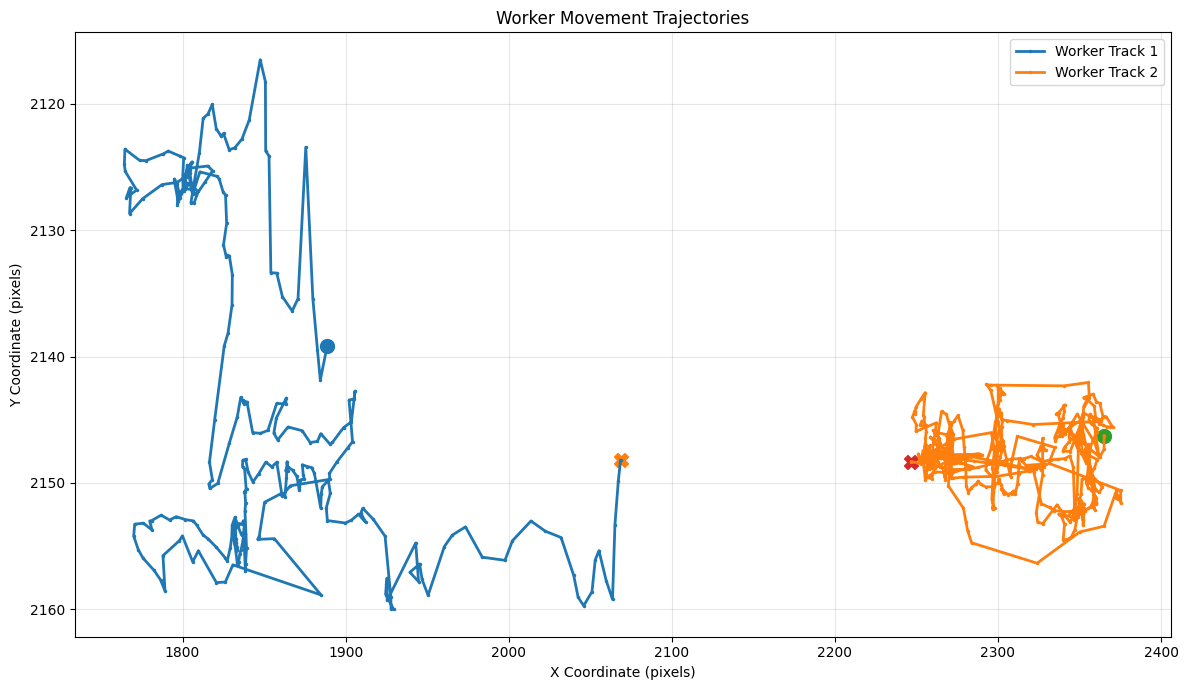

In [23]:

# STEP 3: WORKER TRAJECTORY VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for track_id, group in person_df.groupby("track_id"):
    plt.plot(
        group["bottom_x"],
        group["bottom_y"],
        marker=".",
        markersize=3,
        linewidth=2,
        label=f"Worker Track {track_id}"
    )

    # Mark starting and ending positions
    plt.scatter(
        group["bottom_x"].iloc[0],
        group["bottom_y"].iloc[0],
        marker="o",
        s=100
    )

    plt.scatter(
        group["bottom_x"].iloc[-1],
        group["bottom_y"].iloc[-1],
        marker="X",
        s=100
    )

plt.title("Worker Movement Trajectories")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.legend()
plt.grid(alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Inference / interpretation

The plot is useful for qualitative movement interpretation. It cannot establish metres, speed in km/h, or a collision trajectory without calibration and contextual labels.

## Cell 30 — Check entry into a sample restricted zone

**Input:** `person_df` and a manually configured rectangle defined by `ZONE_X1`, `ZONE_Y1`, `ZONE_X2`, and `ZONE_Y2`.  
**Process:** Checks whether each person's bottom-centre point lies within the rectangle, extracts matching rows, and plots the rectangle with trajectories.  
**Output:** `zone_events`, counts of in-zone observations and tracks, and a zone/trajectory visualization.  
**Inference:** In this run, 508 person observations from Track 2 fell inside the configured sample rectangle. The rectangle was placed around Track 2's observed region for demonstration; therefore these are sample-zone matches, not independently verified safety violations.

RESTRICTED ZONE MONITORING
Total worker observations: 824
Observations inside sample zone: 508
Unique tracks entering zone: 1


,frame,timestamp,track_id,bottom_x,bottom_y,confidence
308,0,0.00,2,2365.078613,2146.258301,0.830477
309,1,0.02,2,2365.024414,2147.349609,0.829599
310,2,0.04,2,2362.374512,2147.959961,0.823281
311,3,0.06,2,2342.801270,2145.793213,0.797754
312,4,0.08,2,2348.616211,2144.547119,0.787165
313,5,0.10,2,2359.435547,2146.850830,0.807905
314,6,0.12,2,2361.815430,2147.853027,0.801888
315,7,0.14,2,2361.964355,2147.960205,0.796939
316,8,0.16,2,2358.518555,2144.887695,0.771606
317,9,0.18,2,2352.316406,2144.439209,0.783829


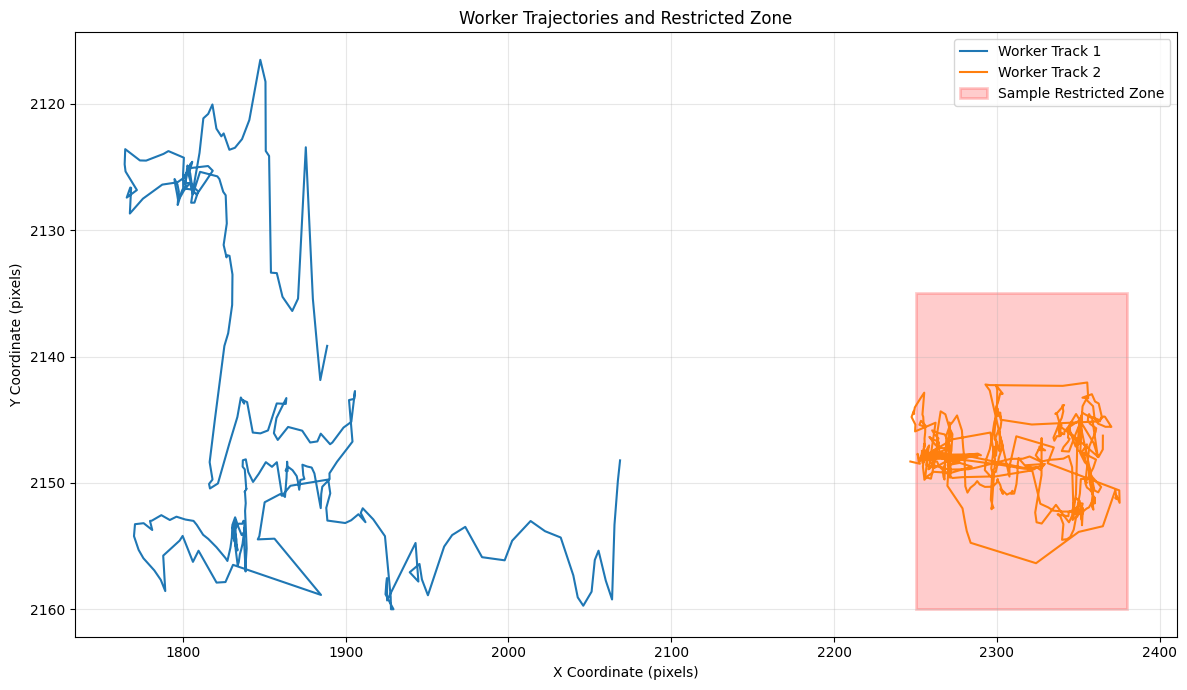

In [24]:

# STEP 4: RESTRICTED ZONE MONITORING

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

# Define a configurable sample restricted zone
ZONE_X1 = 2250
ZONE_Y1 = 2135
ZONE_X2 = 2380
ZONE_Y2 = 2160

# Check whether a worker's bottom-centre point is inside the zone
person_df["inside_restricted_zone"] = (
    (person_df["bottom_x"] >= ZONE_X1) &
    (person_df["bottom_x"] <= ZONE_X2) &
    (person_df["bottom_y"] >= ZONE_Y1) &
    (person_df["bottom_y"] <= ZONE_Y2)
)

# Identify intrusion observations
zone_events = person_df[
    person_df["inside_restricted_zone"]
].copy()

print("RESTRICTED ZONE MONITORING")
print("Total worker observations:", len(person_df))
print("Observations inside sample zone:", len(zone_events))
print("Unique tracks entering zone:",
      zone_events["track_id"].nunique())

display(
    zone_events[
        ["frame", "timestamp", "track_id",
         "bottom_x", "bottom_y", "confidence"]
    ].head(15)
)

# Visualize the zone and worker trajectories
fig, ax = plt.subplots(figsize=(12, 7))

for track_id, group in person_df.groupby("track_id"):
    ax.plot(
        group["bottom_x"],
        group["bottom_y"],
        label=f"Worker Track {track_id}",
        linewidth=1.5
    )

zone = patches.Rectangle(
    (ZONE_X1, ZONE_Y1),
    ZONE_X2 - ZONE_X1,
    ZONE_Y2 - ZONE_Y1,
    linewidth=2,
    edgecolor="red",
    facecolor="red",
    alpha=0.2,
    label="Sample Restricted Zone"
)

ax.add_patch(zone)

ax.set_title("Worker Trajectories and Restricted Zone")
ax.set_xlabel("X Coordinate (pixels)")
ax.set_ylabel("Y Coordinate (pixels)")
ax.invert_yaxis()
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Inference / interpretation

The count is the number of frame observations whose footpoint is inside the rectangle, not the number of unique incidents. Zone placement determines the result.

## Cell 31 — Group zone observations into events and assign a rule score

**Input:** `person_df` with the `inside_restricted_zone` Boolean column created in Cell 30.  
**Process:** Sorts each track by frame, keeps in-zone observations, splits episodes when consecutive observed frames have a gap, calculates episode duration, and applies a simple duration-based score.  
**Output:** `events` with entry/exit frames, timestamps, observation count, average confidence, duration, score, and Low/Medium/High label.  
**Inference:** The observed output contains two episodes for Track 2: one lasting 10 seconds and one lasting 0.12 seconds. The scores (80 and 25) are illustrative rules chosen for this prototype; they are not learned risk probabilities or validated safety thresholds. A frame gap causes an episode split.

In [25]:

# STEP 5: RISK EVENT IDENTIFICATION

import pandas as pd
import numpy as np

# Sort observations chronologically for each track
risk_df = person_df.sort_values(
    ["track_id", "frame"]
).copy()

# Identify changes in zone status
risk_df["status_change"] = (
    risk_df.groupby("track_id")["inside_restricted_zone"]
    .transform(lambda x: x.ne(x.shift()).cumsum())
)

# Keep only observations inside the zone
intrusions = risk_df[
    risk_df["inside_restricted_zone"]
].copy()

# Group continuous intrusion observations into episodes
intrusions["event_id"] = (
    intrusions.groupby("track_id")["frame"]
    .transform(lambda x: x.diff().fillna(1).ne(1).cumsum())
)

events = (
    intrusions.groupby(["track_id", "event_id"])
    .agg(
        entry_frame=("frame", "min"),
        exit_frame=("frame", "max"),
        entry_time=("timestamp", "min"),
        exit_time=("timestamp", "max"),
        observations=("frame", "count"),
        avg_confidence=("confidence", "mean")
    )
    .reset_index()
)

events["duration_seconds"] = (
    events["exit_time"] - events["entry_time"]
)

# Transparent prototype risk scoring:
# Duration-based score, not a learned accident probability
events["risk_score"] = np.select(
    [
        events["duration_seconds"] >= 5,
        events["duration_seconds"] >= 2
    ],
    [80, 50],
    default=25
)

events["risk_level"] = np.select(
    [
        events["risk_score"] >= 70,
        events["risk_score"] >= 40
    ],
    ["High", "Medium"],
    default="Low"
)

print("RESTRICTED ZONE EVENT REPORT")
display(events.round(2))

print("\nRISK LEVEL SUMMARY")
display(
    events["risk_level"].value_counts()
    .rename_axis("risk_level")
    .reset_index(name="event_count")
)


RESTRICTED ZONE EVENT REPORT


,track_id,event_id,entry_frame,exit_frame,entry_time,exit_time,observations,avg_confidence,duration_seconds,risk_score,risk_level
0,2,0,0,500,0.00,10.00,501,0.83,10.00,80,High
1,2,1,508,514,10.16,10.28,7,0.85,0.12,25,Low



RISK LEVEL SUMMARY


,risk_level,event_count
0,High,1
1,Low,1


### Inference / interpretation

Event grouping merges consecutive in-zone frames and splits at gaps. The risk label is a rule output and must not be described as a model prediction.

## Cell 32 — Build the safety monitoring dashboard

**Input:** `person_df`, `zone_events`, and `events`.  
**Process:** Counts tracked workers, person observations, zone observations, and episodes; plots zone observations by track and episode counts by risk label.  
**Output:** Two charts and a printed monitoring summary.  
**Inference:** In this run, two person tracks contributed 824 person observations; 508 observations matched the sample zone; two episodes were reported, one High and one Low under the configured rule. These figures describe this clip and sample zone only.

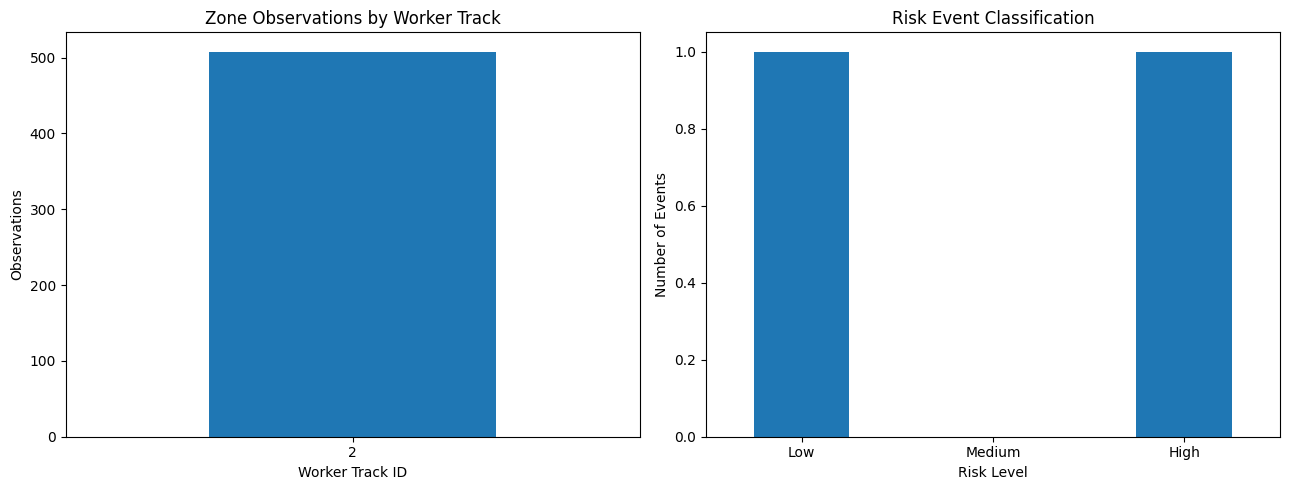

CONSTRUCTION SAFETY MONITORING SUMMARY
--------------------------------------
Tracked workers: 2
Person observations: 824
Zone observations: 508
Intrusion episodes: 2


In [26]:

# STEP 6: SAFETY MONITORING DASHBOARD

import matplotlib.pyplot as plt

total_workers = person_df["track_id"].nunique()
total_observations = len(person_df)
total_intrusions = len(zone_events)
total_events = len(events)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Zone observations by track
track_counts = (
    zone_events.groupby("track_id").size()
)

track_counts.plot(
    kind="bar",
    ax=axes[0],
    title="Zone Observations by Worker Track"
)

axes[0].set_xlabel("Worker Track ID")
axes[0].set_ylabel("Observations")
axes[0].tick_params(axis="x", rotation=0)

# Chart 2: Risk event counts
if total_events > 0:
    events["risk_level"].value_counts().reindex(
        ["Low", "Medium", "High"], fill_value=0
    ).plot(
        kind="bar",
        ax=axes[1],
        title="Risk Event Classification"
    )
else:
    axes[1].text(0.5, 0.5, "No intrusion events",
                 ha="center", va="center")
    axes[1].set_title("Risk Event Classification")

axes[1].set_xlabel("Risk Level")
axes[1].set_ylabel("Number of Events")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("CONSTRUCTION SAFETY MONITORING SUMMARY")
print("--------------------------------------")
print("Tracked workers:", total_workers)
print("Person observations:", total_observations)
print("Zone observations:", total_intrusions)
print("Intrusion episodes:", total_events)


### Inference / interpretation

Dashboard counts summarize the configured sample. The charts are descriptive, not a validation report or evidence of accident prevention.

## Cell 33 — Export analysis tables and trajectory plot

**Input:** The processed tracking, movement, zone, and event DataFrames.  
**Process:** Creates an output directory, writes four CSV files, and saves the worker trajectory plot as a PNG.  
**Output:** `worker_tracking_data.csv`, `worker_movement_summary.csv`, `restricted_zone_observations.csv`, `risk_event_report.csv`, and `worker_trajectories.png`.  
**Inference:** These files make the analysis reusable outside the notebook. They are stored in the current Colab runtime unless downloaded or copied to persistent storage.

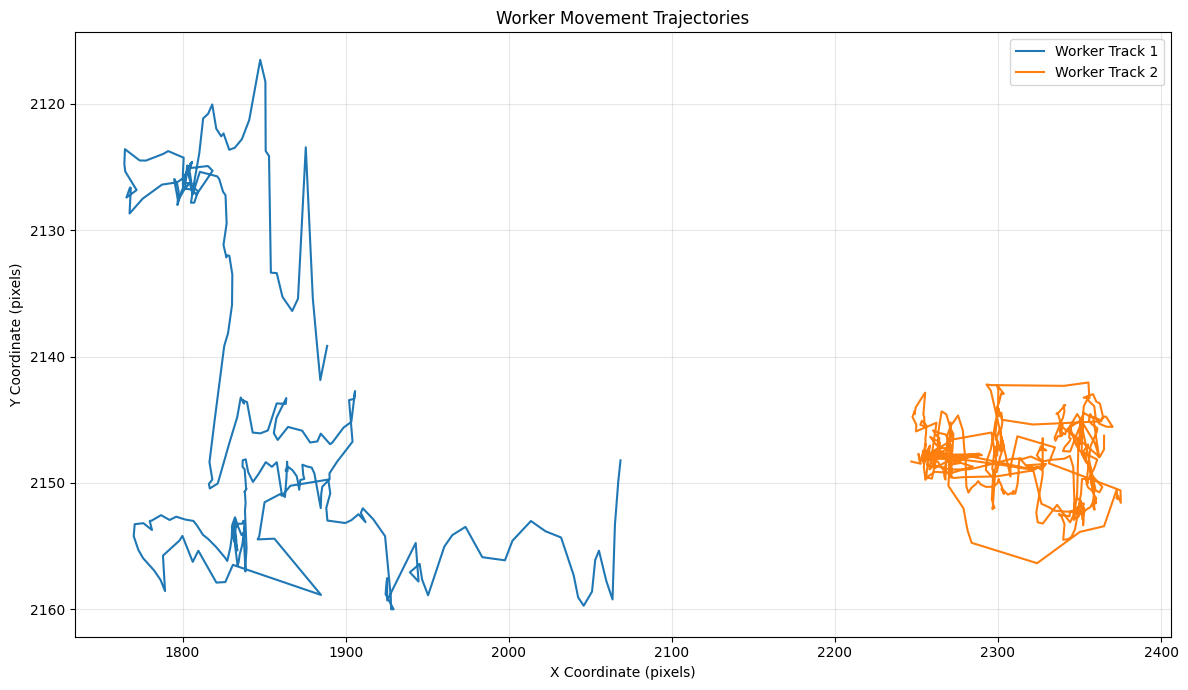

PROJECT OUTPUTS EXPORTED SUCCESSFULLY
restricted_zone_observations.csv
worker_movement_summary.csv
worker_trajectories.png
risk_event_report.csv
worker_tracking_data.csv


In [27]:

# STEP 7: EXPORT PROJECT RESULTS

import os
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "/content/construction_safety_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Export processed tracking data
person_df.to_csv(
    f"{OUTPUT_DIR}/worker_tracking_data.csv",
    index=False
)

# Export movement summary
movement_summary.to_csv(
    f"{OUTPUT_DIR}/worker_movement_summary.csv",
    index=False
)

# Export restricted-zone observations
zone_events.to_csv(
    f"{OUTPUT_DIR}/restricted_zone_observations.csv",
    index=False
)

# Export risk-event report
events.to_csv(
    f"{OUTPUT_DIR}/risk_event_report.csv",
    index=False
)

# Save trajectory plot
plt.figure(figsize=(12, 7))

for track_id, group in person_df.groupby("track_id"):
    plt.plot(
        group["bottom_x"],
        group["bottom_y"],
        label=f"Worker Track {track_id}"
    )

plt.title("Worker Movement Trajectories")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.gca().invert_yaxis()
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/worker_trajectories.png",
    dpi=200
)
plt.show()

print("PROJECT OUTPUTS EXPORTED SUCCESSFULLY")

for filename in os.listdir(OUTPUT_DIR):
    print(filename)


### Inference / interpretation

Confirm that all expected filenames are listed. Download or persist the folder before the Colab runtime disconnects.

## Cell 34 — Package the results for download

**Input:** The output directory created in Cell 33.  
**Process:** Compresses the output folder into a ZIP archive and triggers a Colab file download.  
**Output:** `construction_safety_project_results.zip`.  
**Inference:** The ZIP contains the exported analysis artifacts. It does not contain the original video or the notebook unless those files are separately added.

In [28]:

import shutil

shutil.make_archive(
    "/content/construction_safety_project_results",
    "zip",
    OUTPUT_DIR
)

from google.colab import files

files.download(
    "/content/construction_safety_project_results.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Inference / interpretation

After the browser download completes, keep both the ZIP and the original notebook. The ZIP is an output bundle, not a complete reproducibility package.

## Conclusion

The project demonstrates an AI-assisted construction site safety monitoring prototype using computer vision and object tracking techniques.

A YOLO-based object detection model was used to identify people in video footage, while ByteTrack maintained object identities across consecutive frames. Worker trajectories were generated using bounding-box coordinates, and movement features such as pixel displacement and trajectory distance were calculated.

A configurable restricted-zone monitoring mechanism was implemented to identify worker observations inside a predefined region. Consecutive intrusion observations were grouped into events and assigned rule-based risk scores according to their duration.

The prototype demonstrates how video analytics can support automated worker monitoring and generate structured safety-event reports.

### Limitations

- The current demonstration uses a limited video sample.
- Restricted-zone coordinates are manually configured.
- Risk scores are rule-based and are not trained accident probabilities.
- Worker–machinery interactions have not been validated.
- Pixel measurements are not equivalent to physical distances.
- No independent ground-truth accident dataset was used to validate predictive performance.

### Future Scope

- Integrate multiple construction-site CCTV feeds.
- Train construction-specific object detection models.
- Implement PPE compliance monitoring.
- Detect worker–machinery proximity and unsafe interactions.
- Incorporate temporal machine learning models using labelled safety-event data.
- Develop a real-time safety dashboard and automated alert system.

The project establishes a foundation for extending conventional video surveillance into intelligent construction-site safety monitoring.